### Agentchat with Assistant Agent

Autogen Agent are bydefult stateful

In [1]:
from autogen_agentchat.agents import AssistantAgent
from autogen_ext.models.openai import OpenAIChatCompletionClient
from dotenv import load_dotenv
import os

In [2]:
load_dotenv()

True

In [3]:
os.environ["AICREDITS_API_KEY"]=os.getenv("AICREDITS_API_KEY")
api_key=os.environ["AICREDITS_API_KEY"]
os.environ["BASE_URL"]=os.getenv("BASE_URL")
base_url=os.environ["BASE_URL"]
os.environ["OPENROUTER_API_KEY"]=os.getenv("OPENROUTER_API_KEY")
openrouter_api_key=os.environ["OPENROUTER_API_KEY"]

In [4]:
model_client = OpenAIChatCompletionClient(model='gpt-5-nano', api_key=api_key, base_url=base_url)

In [5]:
my_assistant = AssistantAgent(name="Assistant", model_client=model_client)

# Run a task
result = await my_assistant.run(task="Tell me something about you?")
print(result)

messages=[TextMessage(id='642276eb-4983-46b8-8f19-4cb85f64f581', source='user', models_usage=None, metadata={}, created_at=datetime.datetime(2026, 9, 12, 10, 58, 48, 880308, tzinfo=datetime.timezone.utc), content='Tell me something about you?', type='TextMessage'), TextMessage(id='aa7fee5b-c322-4d9b-b9c9-ac41b3d4291f', source='Assistant', models_usage=RequestUsage(prompt_tokens=41, completion_tokens=1705), metadata={}, created_at=datetime.datetime(2026, 9, 12, 10, 59, 1, 275871, tzinfo=datetime.timezone.utc), content='I’m an AI assistant built by OpenAI. I’m a large language model designed to generate helpful, text-based responses to a wide range of questions and tasks.\n\nA quick snapshot:\n- What I can do: explain concepts, write and edit text, help with coding, brainstorm ideas, translate or summarize, plan projects, tutor, and more.\n- How I work: I generate responses based on patterns in data I was trained on (knowledge up to around 2024). I don’t access real-time internet unless 

In [6]:
result = await my_assistant.run(task="what was my last question")
result

TaskResult(messages=[TextMessage(id='3d3357ca-2457-4dc3-9246-4608ddf71eff', source='user', models_usage=None, metadata={}, created_at=datetime.datetime(2026, 9, 12, 10, 59, 47, 210012, tzinfo=datetime.timezone.utc), content='what was my last question', type='TextMessage'), TextMessage(id='830e149c-e43d-46f6-8111-c21363c13567', source='Assistant', models_usage=RequestUsage(prompt_tokens=280, completion_tokens=472), metadata={}, created_at=datetime.datetime(2026, 9, 12, 10, 59, 51, 655189, tzinfo=datetime.timezone.utc), content='Your last question was: "Tell me something about you?"\n\nTERMINATE', type='TextMessage')], stop_reason=None)

In [7]:
result = await my_assistant.run(task="what was my 2nd question & their answer")
result

TaskResult(messages=[TextMessage(id='d5dbc9b2-32fa-4c45-ad34-87c3e012e1a8', source='user', models_usage=None, metadata={}, created_at=datetime.datetime(2026, 9, 12, 11, 9, 37, 833348, tzinfo=datetime.timezone.utc), content='what was my 2nd question & their answer', type='TextMessage'), TextMessage(id='f6c92df5-cb75-431c-a117-44d48e3ad9ff', source='Assistant', models_usage=RequestUsage(prompt_tokens=316, completion_tokens=932), metadata={}, created_at=datetime.datetime(2026, 9, 12, 11, 9, 45, 111996, tzinfo=datetime.timezone.utc), content='2nd question: what was my last question\nAnswer: Your last question was: "Tell me something about you?"\n\nTERMINATE', type='TextMessage')], stop_reason=None)

In [8]:
agent_state = await my_assistant.save_state()
agent_state

{'type': 'AssistantAgentState',
 'version': '1.0.0',
 'llm_context': {'messages': [{'content': 'Tell me something about you?',
    'source': 'user',
    'type': 'UserMessage'},
   {'content': 'I’m an AI assistant built by OpenAI. I’m a large language model designed to generate helpful, text-based responses to a wide range of questions and tasks.\n\nA quick snapshot:\n- What I can do: explain concepts, write and edit text, help with coding, brainstorm ideas, translate or summarize, plan projects, tutor, and more.\n- How I work: I generate responses based on patterns in data I was trained on (knowledge up to around 2024). I don’t access real-time internet unless you ask me to use tools. I don’t know personal details about you unless you share them in this chat, and I don’t remember past conversations after the chat ends.\n- What I can’t do: give professional medical or legal advice, perform real-world actions, or guarantee perfect accuracy—I can make mistakes.\n- How to get the best resu

### MultiModalMessage


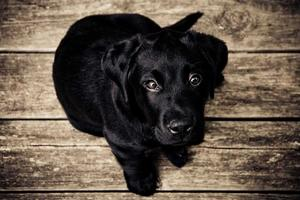

In [9]:
from io import BytesIO

import PIL
import requests
from autogen_agentchat.messages import MultiModalMessage
from autogen_core import Image

# Create a multi-modal message with random image and text.
pil_image = PIL.Image.open(BytesIO(requests.get("https://picsum.photos/id/237/300/200").content))
img = Image(pil_image)
multi_modal_message = MultiModalMessage(content=["Can you describe the content of this image?", img], source="user")
img

In [10]:
result = await my_assistant.run(task=multi_modal_message)
result

TaskResult(messages=[MultiModalMessage(id='1e8b5aef-dce2-4277-a271-300ad9f861c3', source='user', models_usage=None, metadata={}, created_at=datetime.datetime(2026, 9, 12, 11, 54, 33, 57295, tzinfo=datetime.timezone.utc), content=['Can you describe the content of this image?', <autogen_core._image.Image object at 0x000001F05A1AC440>], type='MultiModalMessage'), TextMessage(id='5ab374e1-774a-41d6-8733-4d06223d2cd2', source='Assistant', models_usage=RequestUsage(prompt_tokens=467, completion_tokens=702), metadata={}, created_at=datetime.datetime(2026, 9, 12, 12, 1, 11, 286698, tzinfo=datetime.timezone.utc), content='A black dog with a short, glossy coat is sitting on a wooden floor, looking up at the camera. It has dark eyes and floppy ears, and the background consists of weathered wooden floorboards with warm lighting. The dog appears calm and attentive. TERMINATE', type='TextMessage')], stop_reason=None)

In [13]:
result.messages[-1].content

'A black dog with a short, glossy coat is sitting on a wooden floor, looking up at the camera. It has dark eyes and floppy ears, and the background consists of weathered wooden floorboards with warm lighting. The dog appears calm and attentive. TERMINATE'

### Structured Response

In [12]:
from pydantic import BaseModel
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="pydantic")

class PlanetInfo(BaseModel):
    name: str
    color: str
    distance: str
    unique_identity: str

structured_model_client = OpenAIChatCompletionClient(
    model="google/gemini-2.5-flash",
    api_key=api_key, 
    base_url=base_url,
    model_info={
        "vision": False,
        "function_calling": True,
        "json_output": False,
        "family": "gemini",
        "structured_output": True,
    },
    response_format=PlanetInfo
)

structured_agent = AssistantAgent(model_client=structured_model_client, name = "structured_assistant")

result = await structured_agent.run(task="Tell me about Mars")
result

TaskResult(messages=[TextMessage(id='eb2a606f-5ae6-4622-bb5d-a95aad9c3a6e', source='user', models_usage=None, metadata={}, created_at=datetime.datetime(2026, 9, 12, 12, 25, 40, 563271, tzinfo=datetime.timezone.utc), content='Tell me about Mars', type='TextMessage'), TextMessage(id='791cbe0d-7061-45f0-a204-09ad21bac899', source='structured_assistant', models_usage=RequestUsage(prompt_tokens=28, completion_tokens=99), metadata={}, created_at=datetime.datetime(2026, 9, 12, 12, 25, 45, 89430, tzinfo=datetime.timezone.utc), content='{\n  "name": "Mars",\n  "color": "Red, brown, and gold",\n  "distance": "142 million miles (228 million km) from the Sun",\n  "unique_identity": "The fourth planet from the Sun and the second-smallest planet in the Solar System. Mars is often referred to as the \'Red Planet\' because of the iron oxide prevalent on its surface, which gives it a reddish appearance."\n}', type='TextMessage')], stop_reason=None)

In [13]:
print(result.messages[-1].content)

{
  "name": "Mars",
  "color": "Red, brown, and gold",
  "distance": "142 million miles (228 million km) from the Sun",
  "unique_identity": "The fourth planet from the Sun and the second-smallest planet in the Solar System. Mars is often referred to as the 'Red Planet' because of the iron oxide prevalent on its surface, which gives it a reddish appearance."
}
